# Reference: grid cell labels and lookup

Explain cell labels, rows, columns, start from where

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.grid
import isopods.stick
import isopods.convert

Set up a grid that is 7 cells wide and 3 cells tall:

In [2]:
# Prepare some variables
cell_size = 1
bbox = (0, 0, 7, 3)
transform_dict = isopods.grid.make_transform_dict(
    bbox, cell_size, cell_size)

In [3]:
transform_dict

{'xmin': 0,
 'ymax': 3,
 'cell_width': 1,
 'cell_height': 1,
 'n_cols': 7,
 'n_rows': 3,
 'xmax': 7,
 'ymin': 0}

Find the setup for the plot based on this grid. This uses the normal grid function with a test setting that returns each cell's row and column number.

In [4]:
df_props = isopods.stick.stick_shapes_to_grid(
    None, **transform_dict, _test_grid_layout=True)

100.0% of cells checked

In [5]:
df_props.head(3)

,cell_row,cell_col
cell_label,,
0,0,0
1,1,0
2,2,0


Convert this to a 2D array using the cell label as the data:

In [6]:
arr_labels = isopods.convert.convert_df_to_2darray(
    df_props.reset_index(), 'cell_label', **transform_dict)
# For plotting:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

In [7]:
arr_labels

masked_array(
  data=[[0, 3, 6, 9, 12, 15, 18],
        [1, 4, 7, 10, 13, 16, 19],
        [2, 5, 8, 11, 14, 17, 20]],
  mask=[[False, False, False, False, False, False, False],
        [False, False, False, False, False, False, False],
        [False, False, False, False, False, False, False]],
  fill_value=999999)

Check that all grid values match the dataframe:

In [8]:
for cell_label in df_props.index:
    x = df_props.loc[cell_label, 'cell_col']
    y = df_props.loc[cell_label, 'cell_row']
    val = arr_labels[y, x]
    if val != cell_label:
        print(cell_label, val, x, y)

Plot resulting grid cell labels:

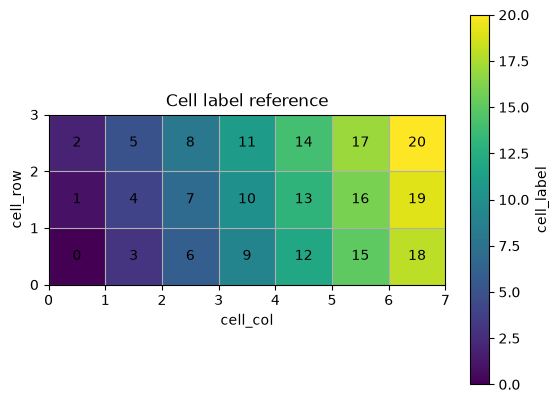

In [9]:
fig, ax = plt.subplots()

# Heat map of cell label data.
# Make sure origin='lower'.
c = ax.imshow(arr_labels, origin='lower', cmap='viridis', extent=extent)
plt.colorbar(c, label='cell_label')
# Annotate labels:
for cell_label in df_props.index:
    coords = df_props.loc[cell_label, ['cell_col', 'cell_row']].values
    coords = [coords[0] + transform_dict['cell_width'] * 0.5,
              coords[1] + transform_dict['cell_height'] * 0.5]
    ax.annotate(cell_label, xy=coords, ha='center', va='center')

# Grid lines:
ax.xaxis.set_major_locator(ticker.MultipleLocator(
    transform_dict['cell_width'], offset=transform_dict['xmin']))
ax.yaxis.set_major_locator(ticker.MultipleLocator(
    transform_dict['cell_height'], offset=transform_dict['ymin']))
ax.grid(which='major')

ax.set_xlim(transform_dict['xmin'], transform_dict['xmax'])
ax.set_ylim(transform_dict['ymin'], transform_dict['ymax'])
ax.set_aspect('equal')

ax.set_title('Cell label reference')
ax.set_xlabel('cell_col')
ax.set_ylabel('cell_row')

plt.show()